Starting device collision analysis for RV_Collision...
Analysis for devices: ['Micra', 'AveirAR', 'AveirVR']
Analysis for lengths: [15, 20, 25, 30, 35, 40, 45]
Total data points: 68943

OVERALL ANALYSIS (All AHA Regions Combined)

Summary Statistics by Device and Length:
                count     mean      std  median   min    max
device  length                                              
AveirAR 15       3283   5.1173   9.6026     0.0   0.0   40.0
        20       3283  10.8864  15.0817     0.0   0.0   60.0
        25       3283  22.8419  23.6969    20.0   0.0   80.0
        30       3283  37.7795  26.1559    40.0   0.0   90.0
        35       3283  57.5663  23.3698    60.0  10.0  100.0
        40       3283  83.3171  13.5387    80.0  50.0  100.0
        45       3283  96.5885   5.8882   100.0  80.0  100.0
AveirVR 15       3283   5.4554   9.8464     0.0   0.0   40.0
        20       3283  11.5961  16.6298     0.0   0.0   80.0
        25       3283  23.3110  23.6217    20.0   0.0   8

/home/alee9/anaconda3/envs/py_vista/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2261: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  warnings.warn(msg, ConvergenceWarning)


              Mixed Linear Model Regression Results
Model:               MixedLM  Dependent Variable:  collision_value
No. Observations:    68943    Method:              REML           
No. Groups:          1        Scale:               332.2552       
Min. group size:     68943    Log-Likelihood:      -297966.8586   
Max. group size:     68943    Converged:           Yes            
Mean group size:     68943.0                                      
------------------------------------------------------------------
                      Coef.  Std.Err.    z    P>|z|  [0.025 0.975]
------------------------------------------------------------------
Intercept              5.220   18.210   0.287 0.774 -30.470 40.911
C(device)[T.AveirVR]   0.671    0.170   3.948 0.000   0.338  1.005
C(device)[T.Micra]    -0.780    0.170  -4.586 0.000  -1.113 -0.446
C(length)[T.20]        5.692    0.260  21.913 0.000   5.183  6.201
C(length)[T.25]       17.224    0.260  66.310 0.000  16.715 17.733
C(length)[

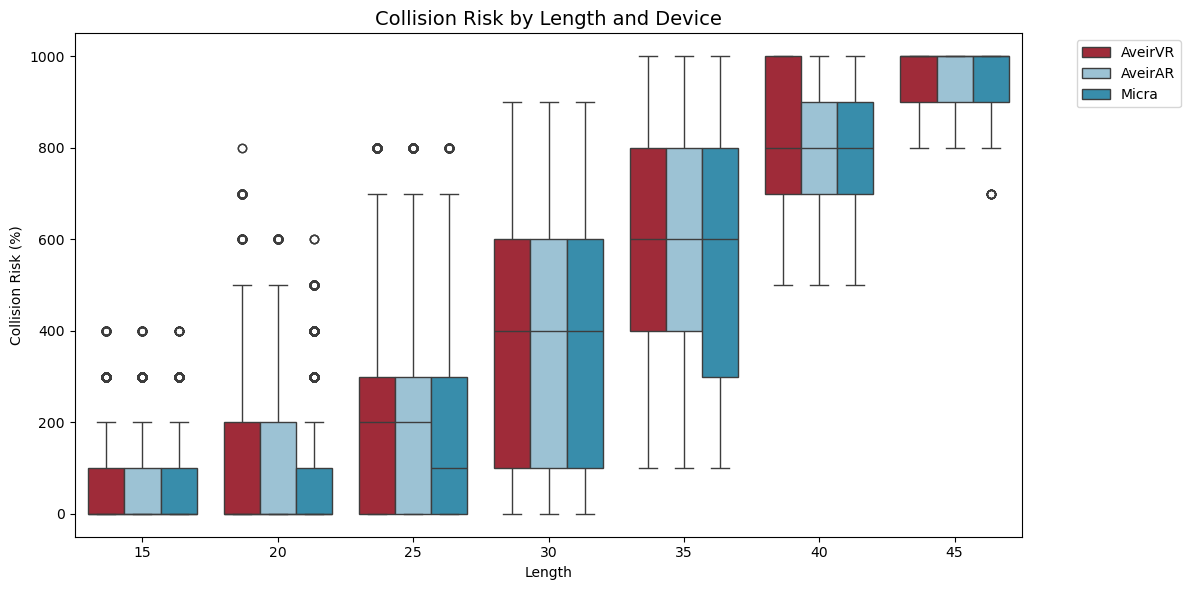

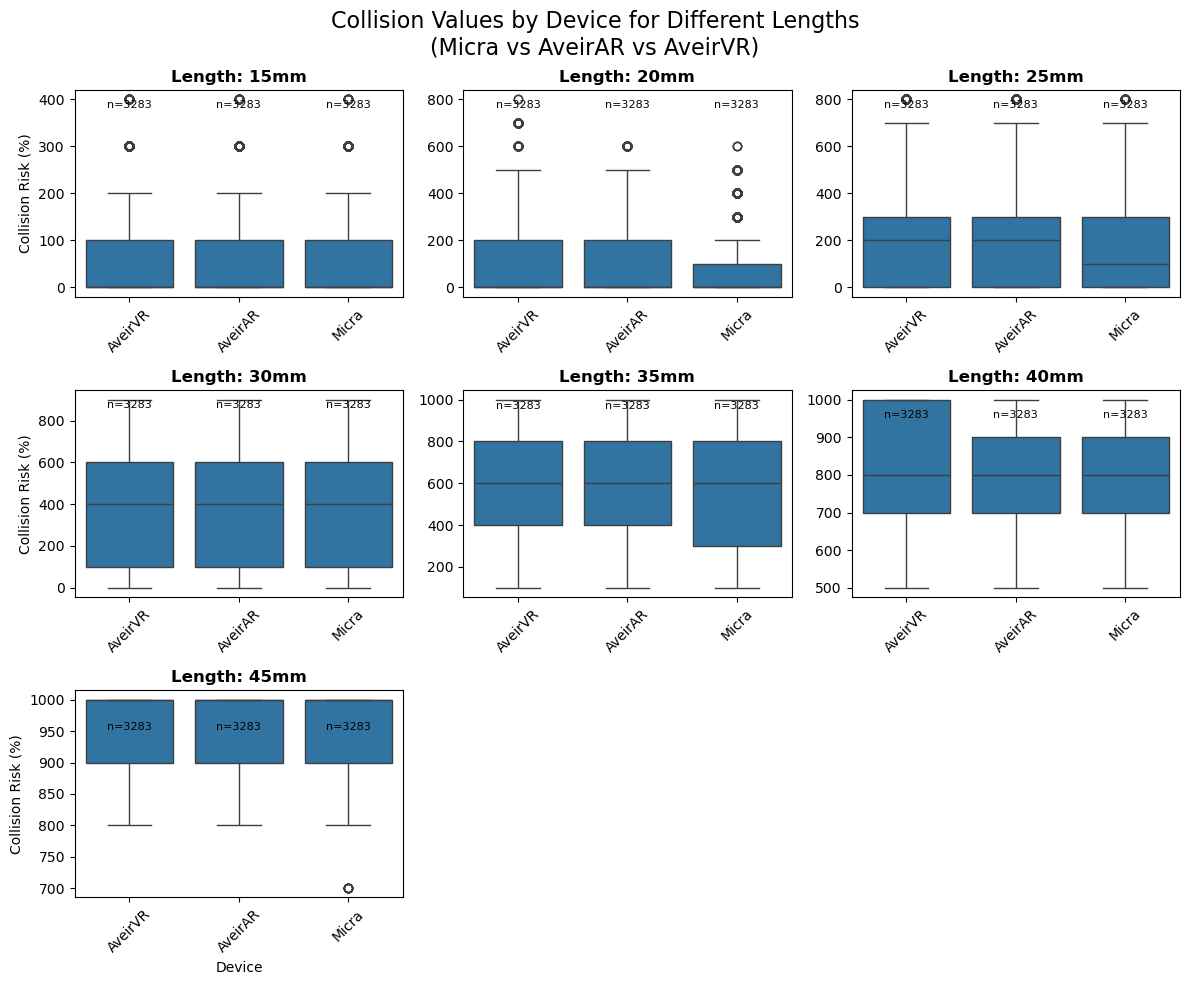


Statistical Summary by Length and Device:

Length: 15
         count    mean     std  min    max  median
device                                            
AveirAR   3283  51.173  96.026  0.0  400.0     0.0
AveirVR   3283  54.554  98.464  0.0  400.0     0.0
Micra     3283  49.802  92.575  0.0  400.0     0.0

Length: 20
         count     mean      std  min    max  median
device                                              
AveirAR   3283  108.864  150.817  0.0  600.0     0.0
AveirVR   3283  115.961  166.298  0.0  800.0     0.0
Micra     3283  101.462  138.650  0.0  600.0     0.0

Length: 25
         count     mean      std  min    max  median
device                                              
AveirAR   3283  228.419  236.969  0.0  800.0   200.0
AveirVR   3283  233.110  236.217  0.0  800.0   200.0
Micra     3283  210.722  222.201  0.0  800.0   100.0

Length: 30
         count     mean      std  min    max  median
device                                              
AveirAR   3283  37

In [ ]:
# Statistical analysis of the csv files 
import pandas as pd
import numpy as np
import os
import csv
from scipy import stats
from itertools import combinations
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf

def collect_collision_data(collision_field, lengths=[None, 15, 20, 25, 30, 35, 40, 45], verbose=False, AHA_regions=[2, 3, 8, 9, 14],conestr=''):
    """
    Collect collision data for all devices and AHA regions into a DataFrame.
    
    Parameters:
    -----------
    collision_field : str
        The collision field type
    length : float or str
        The length parameter for file naming
    
    Returns:
    --------
    df : pandas.DataFrame
        DataFrame with columns: device, AHA_region, theta, z, collision_value, init_len
    """
    
    # Initialize list to store all data
    all_data = []
    
    # Device specifications
    device_specs = {
        'AveirVR': 38,
        'AveirAR': 32.2,
        'Micra': 25.9
    }
    
    for device in ['AveirVR', 'AveirAR', 'Micra']:
        # Get initial length for this device
        init_len = device_specs.get(device)

        if verbose: 
            print(f'Processing device: {device}, initial length: {init_len}')
        
        if init_len is None:
            print(f'WARNING - DEVICE: {device} is not AveirVR, AveirAR or Micra')
            continue
            
        # Set output path
        if collision_field == 'Combined_Collision':
            images_outpath = f'/data_fast/Work/MS_HF_cohort/images/{device}{conestr}/'
        else:
            images_outpath = f'/data_fast/Work/MS_HF_cohort/images/{device}{conestr}/{collision_field}/'
        
        for length_input in lengths:
            if length_input is None: 
                length = init_len
            else:
                length = length_input

            if verbose: 
                print(f'Processing device: {device}, length: {length}')

            # Process each AHA region
            for AHA_region in AHA_regions:
                csv_region_outfile = f'{images_outpath}/csv/{AHA_region}_L{length}.csv'
                if verbose: 
                    print(f'Processing {csv_region_outfile}')
                
                if os.path.exists(csv_region_outfile):
                    try:
                        with open(csv_region_outfile, 'r') as csvfile:
                            reader = csv.reader(csvfile)
                            header = next(reader)
                            data = [row for row in reader]
                        
                        # Convert to numpy array
                        data = np.array(data, dtype=float)
                        
                        if len(data) > 0:
                            # Extract values
                            theta = data[:, 0]
                            z = data[:, 1]
                            collision_values = data[:, 2]
                            
                            # Add to collection
                            for i in range(len(collision_values)):
                                all_data.append({
                                    'device': device,
                                    'AHA_region': AHA_region,
                                    'theta': theta[i],
                                    'z': z[i],
                                    'collision_value': collision_values[i],
                                    'length': length
                                })
                            if verbose: 
                                print(f'  -> Loaded {len(collision_values)} data points')
                        else:
                            print(f'  -> No data found in file')
                            
                    except Exception as e:
                        print(f'  -> Error reading file: {e}')
                else:
                    print(f'  -> File not found')
        
    # Convert to DataFrame
    df = pd.DataFrame(all_data)
    if verbose: 
        print(f'\nTotal data points collected: {len(df)}')
        print(f'Devices: {df["device"].unique()}')
        print(f'AHA regions: {sorted(df["AHA_region"].unique())}')
    
    return df

def analyze_device_differences(df):
    
    """
    Perform statistical  comparing collision values between devices,
    including ANOVA, pairwise t-tests, and a mixed-effects model.
    
    Parameters:
    -----------
    df : pandas.DataFrame
        DataFrame with 'device', 'collision_value', and 'AHA_region' columns.
    
    Returns:
    --------
    results : dict
        Dictionary containing statistical test results
    """
    
    results = {}

    print("\n" + "="*60)
    print("OVERALL ANALYSIS (All AHA Regions Combined)")
    print("="*60)
    df['collision_value'] *= 10
    # Summary statistics by device
    summary_stats = df.groupby('device')['collision_value'].agg([
        'count', 'mean', 'std', 'median', 'min', 'max'
    ]).round(4)
    print("\nSummary Statistics by Device:")
    print(summary_stats)
    
    print("\n" + "="*60)
    summary_stats = df.groupby(['device', 'AHA_region'])['collision_value'].agg([
        'mean', 'std' ]).round(1)

    #print("\nSummary Statistics by Device and AHA region:")
    #print(summary_stats)

    # Overall ANOVA and pairwise t-tests
    devices = df['device'].unique()
    device_groups = [df[df['device'] == device]['collision_value'].values for device in devices]
    
    f_stat, p_anova = stats.f_oneway(*device_groups)
    results['overall'] = {
        'anova': {'f_stat': f_stat, 'p_value': p_anova},
        'pairwise': {},
        'mixed_effects': {}
    }

    print(f"\nANOVA Test:")
    print(f"F-statistic: {f_stat:.4f}")
    print(f"p-value: {p_anova:.6f}")
    print(f"Significant difference: {'Yes' if p_anova < 0.05 else 'No'}")

    # Pairwise t-tests
    print(f"\nPairwise t-tests (overall):")
    for device1, device2 in combinations(devices, 2):
        group1 = df[df['device'] == device1]['collision_value'].values
        group2 = df[df['device'] == device2]['collision_value'].values
        
        t_stat, p_val = stats.ttest_ind(group1, group2)
        results['overall']['pairwise'][f'{device1}_vs_{device2}'] = {
            't_stat': t_stat, 'p_value': p_val
        }
        
        print(f"  {device1} vs {device2}: t={t_stat:.4f}, p={p_val:.6f} {'*' if p_val < 0.05 else ''}")

    # Mixed Effects Model
    print(f"\nMixed Effects Model (device = fixed, region = random):")
    try:
        model = smf.mixedlm("collision_value ~ device", df, groups=df["AHA_region"])
        mixed_result = model.fit()
        print(mixed_result.summary())
        
        results['overall']['mixed_effects']['summary'] = mixed_result.summary().as_text()
        results['overall']['mixed_effects']['pvalues'] = mixed_result.pvalues.to_dict()
    except Exception as e:
        print(f"  Error fitting mixed effects model: {e}")
        results['overall']['mixed_effects']['error'] = str(e)

    # Analysis by AHA Region
    print("\n" + "="*60)
    print("ANALYSIS BY AHA REGION")
    print("="*60)
    
    results['by_region'] = {}
    
    for region in sorted(df['AHA_region'].unique()):
        print(f"\nAHA Region {region}:")
        region_data = df[df['AHA_region'] == region]
        
        if len(region_data) == 0:
            print("  No data available")
            continue
        
        # Summary stats
        region_stats = region_data.groupby('device')['collision_value'].agg([
            'count', 'mean', 'std'
        ]).round(1)
        print(region_stats)
        
        # Regional ANOVA
        region_groups = [region_data[region_data['device'] == device]['collision_value'].values 
                         for device in devices]
        
        non_empty_groups = [g for g in region_groups if len(g) > 0]
        if len(non_empty_groups) < 2:
            print("  Insufficient data for comparison")
            continue

        f_stat_region, p_anova_region = stats.f_oneway(*non_empty_groups)
        results['by_region'][region] = {
            'anova': {'f_stat': f_stat_region, 'p_value': p_anova_region},
            'pairwise': {}
        }
        
        print(f"  ANOVA: F={f_stat_region:.4f}, p={p_anova_region:.6f} {'*' if p_anova_region < 0.05 else ''}")
        
        # Pairwise t-tests
        available_devices = region_data['device'].unique()
        if len(available_devices) >= 2:
            print(f"  Pairwise comparisons:")
            for device1, device2 in combinations(available_devices, 2):
                group1 = region_data[region_data['device'] == device1]['collision_value'].values
                group2 = region_data[region_data['device'] == device2]['collision_value'].values
                
                if len(group1) > 0 and len(group2) > 0:
                    t_stat, p_val = stats.ttest_ind(group1, group2)
                    results['by_region'][region]['pairwise'][f'{device1}_vs_{device2}'] = {
                        't_stat': t_stat, 'p_value': p_val
                    }
                    
                    print(f"    {device1} vs {device2}: t={t_stat:.4f}, p={p_val:.6f} {'*' if p_val < 0.05 else ''}")
    
    return results

def analyse_length_difference(df, device='Micra'):
    """
    Perform statistical analysis comparing collision values between devices.
    
    Parameters:
    -----------
    df : pandas.DataFrame
        DataFrame with collision data
    
    Returns:
    --------
    results : dict
        Dictionary containing statistical test results
    """
    
    results = {}
    
    # Overall comparison (all regions combined)
    print("\n" + "="*60)
    print("OVERALL ANALYSIS (All AHA Regions Combined)")
    print("="*60)
    df=df[df['device']==device]
    # Summary statistics by device
    summary_stats = df.groupby('length')['collision_value'].agg([
        'count', 'mean', 'std', 'median', 'min', 'max'
    ]).round(4)
    print("\nSummary Statistics by Length:")
    print(summary_stats)

    # Overall ANOVA
    lengths = df['length'].unique()
    length_groups = [df[df['length'] == length]['collision_value'].values for length in lengths]
    f_stat, p_anova = stats.f_oneway(*length_groups)
    results['overall'] = {
        'anova': {'f_stat': f_stat, 'p_value': p_anova},
        'pairwise': {},
        'mixed_effects': {}
    }   

    print(f"\nANOVA Test:")
    print(f"F-statistic: {f_stat:.4f}")
    print(f"p-value: {p_anova:.6f}")
    print(f"Significant difference: {'Yes' if p_anova < 0.05 else 'No'}")       
    # Pairwise t-tests
    print(f"\nPairwise t-tests (overall):")
    for length1, length2 in combinations(lengths, 2):   
        group1 = df[df['length'] == length1]['collision_value'].values
        group2 = df[df['length'] == length2]['collision_value'].values
        
        t_stat, p_val = stats.ttest_ind(group1, group2)
        results['overall']['pairwise'][f'{length1}_vs_{length2}'] = {
            't_stat': t_stat, 'p_value': p_val
        }
        
        print(f"  {length1} vs {length2}: t={t_stat:.4f}, p={p_val:.6f} {'*' if p_val < 0.05 else ''}") 
    # Mixed Effects Model
    print(f"\nMixed Effects Model (length = fixed, region = random):")
    try:        
        model = smf.mixedlm("collision_value ~ length", df, groups=df["AHA_region"])
        mixed_result = model.fit()
        print(mixed_result.summary())
        
        results['overall']['mixed_effects']['summary'] = mixed_result.summary().as_text()
        results['overall']['mixed_effects']['pvalues'] = mixed_result.pvalues.to_dict()
    except Exception as e:
        print(f"  Error fitting mixed effects model: {e}")
        results['overall']['mixed_effects']['error'] = str(e)   

    # Analysis by AHA Region
    print("\n" + "="*60)
    print("ANALYSIS BY AHA REGION")
    print("="*60)           

    results['by_region'] = {}
    for region in sorted(df['AHA_region'].unique()):
        print(f"\nAHA Region {region}:")
        region_data = df[df['AHA_region'] == region]
        
        if len(region_data) == 0:
            print("  No data available")
            continue
        
        # Summary stats
        region_stats = region_data.groupby('length')['collision_value'].agg([
            'count', 'mean', 'std'
        ]).round(4)
        print(region_stats)
        
        # Regional ANOVA
        region_groups = [region_data[region_data['length'] == length]['collision_value'].values 
                         for length in lengths]
        
        non_empty_groups = [g for g in region_groups if len(g) > 0]
        if len(non_empty_groups) < 2:
            print("  Insufficient data for comparison")
            continue

        f_stat_region, p_anova_region = stats.f_oneway(*non_empty_groups)
        results['by_region'][region] = {
            'anova': {'f_stat': f_stat_region, 'p_value': p_anova_region},
            'pairwise': {}
        }
        
        print(f"  ANOVA: F={f_stat_region:.4f}, p={p_anova_region:.6f} {'*' if p_anova_region < 0.05 else ''}")
        
        # Pairwise t-tests
        available_lengths = region_data['length'].unique()
        if len(available_lengths) >= 2:
            print(f"  Pairwise comparisons:")
            for length1, length2 in combinations(available_lengths, 2):
                group1 = region_data[region_data['length'] == length1]['collision_value'].values
                group2 = region_data[region_data['length'] == length2]['collision_value'].values
                
                if len(group1) > 0 and len(group2) > 0:
                    t_stat, p_val = stats.ttest_ind(group1, group2)
                    results['by_region'][region]['pairwise'][f'{length1}_vs_{length2}'] = {
                        't_stat': t_stat, 'p_value': p_val
                    }
                    
                    print(f"    {length1} vs {length2}: t={t_stat:.4f}, p={p_val:.6f} {'*' if p_val < 0.05 else ''}")   

                    
    return results

def analyse_device_length_difference(df, devices=['Micra', 'AveirAR', 'AveirVR'], lengths=list(range(15, 50, 5))):
    """
    Perform statistical analysis comparing collision values between devices and lengths.
    
    Parameters:
    -----------
    df : pandas.DataFrame
        DataFrame with collision data
    devices : list
        List of devices to compare (default: ['Micra', 'AveirAR', 'AveirVR'])
    lengths : list
        List of lengths to compare (default: [15, 20, 25, 30, 35, 40, 45])
    
    Returns:
    --------
    results : dict
        Dictionary containing statistical test results
    """
    
    results = {}
    df['collision_value'] = df['collision_value']*10
    # Filter data for specified devices and lengths
    df_filtered = df[(df['device'].isin(devices)) & (df['length'].isin(lengths))]
    
    print(f"Analysis for devices: {devices}")
    print(f"Analysis for lengths: {lengths}")
    print(f"Total data points: {len(df_filtered)}")
    
    # Overall comparison (all regions combined)
    print("\n" + "="*80)
    print("OVERALL ANALYSIS (All AHA Regions Combined)")
    print("="*80)
    
    # Summary statistics by device and length
    summary_stats = df_filtered.groupby(['device', 'length'])['collision_value'].agg([
        'count', 'mean', 'std', 'median', 'min', 'max'
    ]).round(4)
    print("\nSummary Statistics by Device and Length:")
    print(summary_stats)
    
    # Summary statistics by device only
    device_stats = df_filtered.groupby('device')['collision_value'].agg([
        'count', 'mean', 'std', 'median', 'min', 'max'
    ]).round(4)
    print("\nSummary Statistics by Device:")
    print(device_stats)
    
    # Summary statistics by length only
    length_stats = df_filtered.groupby('length')['collision_value'].agg([
        'count', 'mean', 'std', 'median', 'min', 'max'
    ]).round(4)
    print("\nSummary Statistics by Length:")
    print(length_stats)

    # Two-way ANOVA (device × length)
    print(f"\nTwo-way ANOVA (Device × Length):")
    try:
        import statsmodels.api as sm
        from statsmodels.formula.api import ols
        
        # Two-way ANOVA
        model = ols('collision_value ~ C(device) + C(length) + C(device):C(length)', 
                   data=df_filtered).fit()
        anova_table = sm.stats.anova_lm(model, typ=2)
        print(anova_table)
        
        results['overall'] = {
            'two_way_anova': anova_table.to_dict(),
            'device_comparisons': {},
            'length_comparisons': {},
            'device_length_combinations': {},
            'mixed_effects': {}
        }
    except Exception as e:
        print(f"  Error fitting two-way ANOVA: {e}")
        results['overall'] = {'error': str(e)}

    # Device comparisons (across all lengths)
    print(f"\nDevice Comparisons (across all lengths):")
    device_groups = [df_filtered[df_filtered['device'] == device]['collision_value'].values 
                    for device in devices]
    
    # ANOVA for devices
    f_stat_device, p_anova_device = stats.f_oneway(*device_groups)
    print(f"ANOVA F-statistic: {f_stat_device:.4f}")
    print(f"ANOVA p-value: {p_anova_device:.6f}")
    print(f"Significant difference: {'Yes' if p_anova_device < 0.05 else 'No'}")
    
    # Pairwise t-tests between devices
    print(f"\nPairwise t-tests between devices:")
    for device1, device2 in combinations(devices, 2):
        group1 = df_filtered[df_filtered['device'] == device1]['collision_value'].values
        group2 = df_filtered[df_filtered['device'] == device2]['collision_value'].values
        
        if len(group1) > 0 and len(group2) > 0:
            t_stat, p_val = stats.ttest_ind(group1, group2)
            results['overall']['device_comparisons'][f'{device1}_vs_{device2}'] = {
                't_stat': t_stat, 'p_value': p_val
            }
            
            print(f"  {device1} vs {device2}: t={t_stat:.4f}, p={p_val:.6f} {'*' if p_val < 0.05 else ''}")

    # Length comparisons (across all devices)
    print(f"\nLength Comparisons (across all devices):")
    length_groups = [df_filtered[df_filtered['length'] == length]['collision_value'].values 
                    for length in lengths]
    
    # ANOVA for lengths
    f_stat_length, p_anova_length = stats.f_oneway(*length_groups)
    print(f"ANOVA F-statistic: {f_stat_length:.4f}")
    print(f"ANOVA p-value: {p_anova_length:.6f}")
    print(f"Significant difference: {'Yes' if p_anova_length < 0.05 else 'No'}")
    
    # Pairwise t-tests between lengths
    print(f"\nPairwise t-tests between lengths:")
    for length1, length2 in combinations(lengths, 2):
        group1 = df_filtered[df_filtered['length'] == length1]['collision_value'].values
        group2 = df_filtered[df_filtered['length'] == length2]['collision_value'].values
        
        if len(group1) > 0 and len(group2) > 0:
            t_stat, p_val = stats.ttest_ind(group1, group2)
            results['overall']['length_comparisons'][f'{length1}_vs_{length2}'] = {
                't_stat': t_stat, 'p_value': p_val
            }
            
            print(f"  {length1} vs {length2}: t={t_stat:.4f}, p={p_val:.6f} {'*' if p_val < 0.05 else ''}")

    # Mixed Effects Model
    print(f"\nMixed Effects Model (device + length = fixed, region = random):")
    try:
        model = smf.mixedlm("collision_value ~ C(device) + C(length)", 
                           df_filtered, groups=df_filtered["AHA_region"])
        mixed_result = model.fit()
        print(mixed_result.summary())
        
        results['overall']['mixed_effects']['summary'] = mixed_result.summary().as_text()
        results['overall']['mixed_effects']['pvalues'] = mixed_result.pvalues.to_dict()
    except Exception as e:
        print(f"  Error fitting mixed effects model: {e}")
        results['overall']['mixed_effects']['error'] = str(e)

    # Analysis by Device (comparing lengths within each device)
    print("\n" + "="*80)
    print("ANALYSIS BY DEVICE (comparing lengths within each device)")
    print("="*80)
    
    results['by_device'] = {}
    for device in devices:
        print(f"\nDevice: {device}")
        device_data = df_filtered[df_filtered['device'] == device]
        
        if len(device_data) == 0:
            print("  No data available")
            continue
        
        # Summary stats for this device
        device_length_stats = device_data.groupby('length')['collision_value'].agg([
            'count', 'mean', 'std', 'median'
        ]).round(4)
        print(device_length_stats)
        
        # ANOVA for lengths within this device
        device_length_groups = [device_data[device_data['length'] == length]['collision_value'].values 
                               for length in lengths]
        non_empty_groups = [g for g in device_length_groups if len(g) > 0]
        
        if len(non_empty_groups) < 2:
            print("  Insufficient data for comparison")
            continue
        
        f_stat_device_length, p_anova_device_length = stats.f_oneway(*non_empty_groups)
        results['by_device'][device] = {
            'anova': {'f_stat': f_stat_device_length, 'p_value': p_anova_device_length},
            'pairwise': {}
        }
        
        print(f"  ANOVA: F={f_stat_device_length:.4f}, p={p_anova_device_length:.6f} {'*' if p_anova_device_length < 0.05 else ''}")
        
        # Pairwise comparisons for lengths within this device
        available_lengths = device_data['length'].unique()
        if len(available_lengths) >= 2:
            print(f"  Pairwise length comparisons:")
            for length1, length2 in combinations(available_lengths, 2):
                group1 = device_data[device_data['length'] == length1]['collision_value'].values
                group2 = device_data[device_data['length'] == length2]['collision_value'].values
                
                if len(group1) > 0 and len(group2) > 0:
                    t_stat, p_val = stats.ttest_ind(group1, group2)
                    results['by_device'][device]['pairwise'][f'{length1}_vs_{length2}'] = {
                        't_stat': t_stat, 'p_value': p_val
                    }
                    
                    print(f"    {length1} vs {length2}: t={t_stat:.4f}, p={p_val:.6f} {'*' if p_val < 0.05 else ''}")

    # Analysis by Length (comparing devices within each length)
    print("\n" + "="*80)
    print("ANALYSIS BY LENGTH (comparing devices within each length)")
    print("="*80)
    
    results['by_length'] = {}
    for length in lengths:
        print(f"\nLength: {length}")
        length_data = df_filtered[df_filtered['length'] == length]
        
        if len(length_data) == 0:
            print("  No data available")
            continue
        
        # Summary stats for this length
        length_device_stats = length_data.groupby('device')['collision_value'].agg([
            'count', 'mean', 'std', 'median'
        ]).round(4)
        print(length_device_stats)
        
        # ANOVA for devices within this length
        length_device_groups = [length_data[length_data['device'] == device]['collision_value'].values 
                               for device in devices]
        non_empty_groups = [g for g in length_device_groups if len(g) > 0]
        
        if len(non_empty_groups) < 2:
            print("  Insufficient data for comparison")
            continue
        
        f_stat_length_device, p_anova_length_device = stats.f_oneway(*non_empty_groups)
        results['by_length'][length] = {
            'anova': {'f_stat': f_stat_length_device, 'p_value': p_anova_length_device},
            'pairwise': {}
        }
        
        print(f"  ANOVA: F={f_stat_length_device:.4f}, p={p_anova_length_device:.6f} {'*' if p_anova_length_device < 0.05 else ''}")
        
        # Pairwise comparisons for devices within this length
        available_devices = length_data['device'].unique()
        if len(available_devices) >= 2:
            print(f"  Pairwise device comparisons:")
            for device1, device2 in combinations(available_devices, 2):
                group1 = length_data[length_data['device'] == device1]['collision_value'].values
                group2 = length_data[length_data['device'] == device2]['collision_value'].values
                
                if len(group1) > 0 and len(group2) > 0:
                    t_stat, p_val = stats.ttest_ind(group1, group2)
                    results['by_length'][length]['pairwise'][f'{device1}_vs_{device2}'] = {
                        't_stat': t_stat, 'p_value': p_val
                    }
                    
                    print(f"    {device1} vs {device2}: t={t_stat:.4f}, p={p_val:.6f} {'*' if p_val < 0.05 else ''}")

    # Analysis by AHA Region
    print("\n" + "="*80)
    print("ANALYSIS BY AHA REGION")
    print("="*80)
    
    results['by_region'] = {}
    for region in sorted(df_filtered['AHA_region'].unique()):
        print(f"\nAHA Region {region}:")
        region_data = df_filtered[df_filtered['AHA_region'] == region]
        
        if len(region_data) == 0:
            print("  No data available")
            continue
        
        # Summary stats by device and length within region
        region_stats = region_data.groupby(['device', 'length'])['collision_value'].agg([
            'count', 'mean', 'std'
        ]).round(4)
        print(region_stats)
        
        # Two-way ANOVA within region (if sufficient data)
        try:
            if len(region_data) > 10:  # Minimum threshold for meaningful analysis
                model_region = ols('collision_value ~ C(device) + C(length) + C(device):C(length)', 
                                 data=region_data).fit()
                anova_table_region = sm.stats.anova_lm(model_region, typ=2)
                print(f"  Two-way ANOVA for region {region}:")
                print(anova_table_region)
                
                results['by_region'][region] = {
                    'two_way_anova': anova_table_region.to_dict(),
                    'sample_size': len(region_data)
                }
            else:
                print(f"  Insufficient data for ANOVA (n={len(region_data)})")
                results['by_region'][region] = {'insufficient_data': len(region_data)}
        except Exception as e:
            print(f"  Error in regional analysis: {e}")
            results['by_region'][region] = {'error': str(e)}
    
    return results
def boxplot_collision_by_length(df, length_column='length', 
                               expected_devices=['Micra', 'AveirAR', 'AveirVR'],
                               expected_lengths=[15, 20, 25, 30, 35, 40, 45]):
    """
    Create boxplots comparing collision values between devices for different lengths.
    
    Parameters:
    -----------
    df : pandas.DataFrame
        DataFrame with collision data
    length_column : str, default='length'
        Name of the column containing length data
    expected_devices : list, default=['Micra', 'AveirAR', 'AveirVR']
        List of expected device names
    expected_lengths : list, default=[15, 20, 25, 30, 35, 40, 45]
        List of expected length values
    """
    # import matplotlib.pyplot as plt
    # import seaborn as sns
    # import numpy as np
    
    # Set up the plotting style
    #plt.style.use('default')
    #sns.set_palette("husl")
    
    # Validate data
    #validate_devices(df, expected_devices)
    sns.color_palette("coolwarm", as_cmap=True)

    device_colors = {
        'Micra': '#2596be',
        'OtherPallete': '#f4a582', 
        'AveirVR': '#b2182b',
        'AveirAR': '#92c5de'
    }

    # Check if length column exists
    if length_column not in df.columns:
        print(f"Error: Column '{length_column}' not found in DataFrame")
        print(f"Available columns: {list(df.columns)}")
        return
    
    # Get unique lengths and sort them
    unique_lengths = sorted(df[length_column].unique())
    n_lengths = len(unique_lengths)
    
    # Check for missing lengths
    missing_lengths = set(expected_lengths) - set(unique_lengths)
    if missing_lengths:
        print(f"Warning: Missing expected lengths: {sorted(list(missing_lengths))}")
    
    print(f"Analyzing {len(expected_devices)} devices across {n_lengths} lengths")
    print(f"Devices: {expected_devices}")
    print(f"Lengths: {unique_lengths}")
    print("-" * 60)
    
    # Figure 1: Overall comparison across all lengths
    fig, ax = plt.subplots(1, 1, figsize=(12, 6))
    df['collision_value'] = df['collision_value'].astype(float)*10  # Ensure collision_value is float and scaled to percentage
    # Create boxplot with length on x-axis and collision_value on y-axis, grouped by device
    sns.boxplot(data=df, x=length_column, y='collision_value', hue='device', palette=device_colors, ax=ax)
    ax.set_title('Collision Risk by Length and Device', fontsize=14)
    ax.set_ylabel('Collision Risk (%)')
    ax.set_xlabel('Length')
    ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    
    plt.tight_layout()
    plt.savefig('/data_fast/Work/MS_HF_cohort/images/All_lengths_output.png', dpi=300)
    plt.show()
    
    # Figure 2: Optimized layout for 7 lengths (3 rows x 3 columns, with 2 empty spots)
    if n_lengths > 1:
        # For 7 lengths, use 3x3 grid
        cols = 3
        rows = 3
        
        fig, axes = plt.subplots(rows, cols, figsize=(12, 10))
        fig.suptitle('Collision Values by Device for Different Lengths\n(Micra vs AveirAR vs AveirVR)', fontsize=16)
        
        # Flatten axes for easier indexing
        axes_flat = axes.flatten()
        
        for i, length in enumerate(unique_lengths):
            if i < len(axes_flat):
                length_data = df[df[length_column] == length]
                
                # Create boxplot for this specific length
                sns.boxplot(data=length_data, x='device', y='collision_value', ax=axes_flat[i])
                axes_flat[i].set_title(f'Length: {length}mm', fontweight='bold')
                axes_flat[i].set_ylabel('Collision Risk (%)' if i % cols == 0 else '')
                axes_flat[i].set_xlabel('Device' if i >= (rows-1)*cols else '')
                axes_flat[i].tick_params(axis='x', rotation=45)
                
                # Add sample size annotation
                sample_sizes = length_data.groupby('device').size()
                for j, device in enumerate(length_data['device'].unique()):
                    if device in sample_sizes:
                        axes_flat[i].text(j, axes_flat[i].get_ylim()[1]*0.95, 
                                        f'n={sample_sizes[device]}', 
                                        ha='center', va='top', fontsize=8)
        
        # Hide unused subplots (last 2 spots in 3x3 grid)
        for i in range(n_lengths, len(axes_flat)):
            axes_flat[i].set_visible(False)
        
        plt.tight_layout()
        plt.show()
    
    # Figure 3: Statistical summary
    print("\nStatistical Summary by Length and Device:")
    print("=" * 60)
    
    for length in unique_lengths:
        print(f"\nLength: {length}")
        length_data = df[df[length_column] == length]
        summary = length_data.groupby('device')['collision_value'].agg([
            'count', 'mean', 'std', 'min', 'max', 'median'
        ]).round(3)
        print(summary)
    
    # Figure 4: Violin plot alternative (if there are enough data points)
    # if len(df) > 20:  # Only create violin plot if we have sufficient data
    #     fig, ax = plt.subplots(1, 1, figsize=(12, 6))
        
    #     sns.violinplot(data=df, x=length_column, y='collision_value', hue='device', ax=ax)
    #     ax.set_title('Distribution of Collision Values by Length and Device (Violin Plot)', fontsize=14)
    #     ax.set_ylabel('Collision Risk (%)')
    #     ax.set_xlabel('Length')
    #     ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
        
    #     plt.tight_layout()
        
    #     plt.show()

def create_visualizations(df):
    """
    Create visualizations comparing collision values between devices.
    
    Parameters:
    -----------
    df : pandas.DataFrame
        DataFrame with collision data
    """
    
    # Set up the plotting style
    #plt.style.use('default')
    #sns.set_palette("husl")
    sns.color_palette("coolwarm", as_cmap=True)
    # Create a color mapping for specific devices
    device_colors = {
        'Micra': '#2596be',
        'OtherPallete': '#f4a582', 
        'AveirVR': '#b2182b',
        'AveirAR': '#92c5de'
    }
    # Figure 1: Overall comparison
    fig, axes = plt.subplots(1, 1, figsize=(8, 5))
    #fig.suptitle('Device Collision Value Comparison', fontsize=16)
    
    # Box plot by AHA region
    sns.boxplot(data=df, x='AHA_region', y='collision_value', hue='device',palette=device_colors)   
    axes.set_title('Collision Risk by AHA Region and Device')
    axes.set_ylabel('Collision Risk (%)')
    axes.set_xlabel('AHA Region')
    axes.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    
    plt.tight_layout()
    plt.savefig('/data_fast/Work/MS_HF_cohort/images/Init_length_AHA_regions_output.png', bbox_inches='tight')    

    plt.show()
    
    # Figure 2: Detailed region-by-region comparison
    regions = sorted(df['AHA_region'].unique())
    n_regions = len(regions)
    fig, axes = plt.subplots(1, n_regions, figsize=(4*n_regions, 6))
    if n_regions == 1:
        axes = [axes]
    
    fig.suptitle('Collision Risk by AHA Region', fontsize=16)
    
    for i, region in enumerate(regions):
        region_data = df[df['AHA_region'] == region]
        sns.boxplot(data=region_data, x='device', y='collision_value', ax=axes[i], hue='device',palette=device_colors)   
        axes[i].set_title(f'AHA Region {region}')
        axes[i].set_ylabel('Collision Risk (%)' if i == 0 else '')
        axes[i].tick_params(axis='x', rotation=45)
    plt.tight_layout()
    # Save image to file 
    plt.show()
# Main execution
def process_df(collision_field, length, AHA_regions=[2, 3, 8, 9, 14],conestr=''):
    """
    Main function to run the complete analysis.
    
    Parameters:
    -----------
    collision_field : str
        The collision field type
    length : float or str
        The length parameter
    """
    
    print(f"Starting device collision analysis for {collision_field}...")
    
    # Collect data
    df = collect_collision_data(collision_field, length, AHA_regions=AHA_regions,conestr=conestr)
    
    if len(df) == 0:
        print("No data collected. Please check file paths and data availability.")
        return None, None
    
    # Perform statistical analysis
    if length[0] is None: 
        results = analyze_device_differences(df)
        create_visualizations(df)    
    else: 
        #results = analyse_length_difference(df, device='Micra')

        results=analyse_device_length_difference(df, devices=['Micra', 'AveirAR', 'AveirVR'], lengths=length)
        boxplot_collision_by_length(df, length_column='length', 
                               expected_devices=['Micra', 'AveirAR', 'AveirVR'],
                               expected_lengths=length)
    return df, results

def run_analysis_for_init_len(collision_fields=['Combined_Collision'], AHA_regions=[2, 3, 8, 9, 14],conestr=''): 
    for collision_field in collision_fields: #, 'RV_Collision', 'TV_Collision', 'PM_Collision']:   # Change as needed
        #length = None  # None - uses initial length based on device
        # Only test for initial lengths
        df, results = process_df(collision_field, length=[None],AHA_regions=AHA_regions,conestr=conestr)
    return df, results
def run_analysis_for_all_lens(collision_fields=['Combined_Collision'], AHA_regions=[2, 3, 8, 9, 14], conestr=''): 
    for collision_field in collision_fields: #, 'RV_Collision', 'TV_Collision', 'PM_Collision']:   # Change as needed
        # All lengths comparison
        df, results = process_df(collision_field, length=[15, 20, 25, 30, 35, 40, 45],AHA_regions=AHA_regions,conestr=conestr)  # Example lengths
    return df, results


def initial_analysis(): 
    # Initialise
    df=None
    results=None
    CSP_flag=True

    if CSP_flag: 
        AHA_regions=[20,21,22,23] # LB, AB, PB, SB
        AHA_regions=[22]
    else: 
        AHA_regions=[2, 3, 8, 9, 14]

    collision_fields=['TV_Collision', 'PM_Collision', 'RV_Collision', 'Combined_Collision']
    collision_fields=['RV_Collision']
    # Example usage
    
    #df, results = run_analysis_for_init_len(collision_fields, AHA_regions)
    df, results = run_analysis_for_all_lens(collision_fields, AHA_regions)        
                        
    if df is not None and results is not None:
        print("\nAnalysis completed successfully.")
        print("DataFrame shape:", df.shape)
        print("Results:", results)
    else:
        print("Analysis failed.")

def cone_initial_analysis(): 
    # Initialise
    df=None
    results=None
    CSP_flag=True # Check for conduction system pacing regions
    conestr='_cone10_10'
    
    if CSP_flag: 
        AHA_regions=[20,21,22,23] # LB, AB, PB, SB
        #AHA_regions=[22]
    else: 
        AHA_regions=[2, 3, 8, 9, 14]

    collision_fields=['TV_Collision_Cone', 'PM_Collision_Cone', 'RV_Collision_Cone', 'Combined_Collision_Cone']
    collision_fields=['RV_Collision_Cone']
    # Example usage
    
    #df, results = run_analysis_for_init_len(collision_fields, AHA_regions)
    df, results = run_analysis_for_all_lens(collision_fields, AHA_regions, conestr=conestr)        
                        
    if df is not None and results is not None:
        print("\nAnalysis completed successfully.")
        print("DataFrame shape:", df.shape)
        print("Results:", results)
    else:
        print("Analysis failed.")

if __name__ == "__main__":
    #initial_analysis()
    cone_initial_analysis()

# Example usage:
# df, results = main('Combined_Collision', 30)
# or
# df, results = main('your_collision_field', your_length)

In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import statsmodels.api as sm
from statsmodels.formula.api import ols, mixedlm
from statsmodels.stats.anova import anova_lm

def device_specs(): 
    # Device specifications
    device_specs = {
        'Micra': {
            'volume': 0.913,
            'original_length': 25.90,
            'original_diameter': 6.70,
            'diameters': {15: 8.8, 20: 7.6, 25: 6.8, 30: 6.2, 35: 5.8, 40: 5.4, 45: 5.1}
        },
        'AveirAR': {
            'volume': 1.068,
            'original_length': 32.20,
            'original_diameter': 6.50,
            'diameters': {15: 9.5, 20: 8.2, 25: 7.4, 30: 6.7, 35: 6.2, 40: 5.8, 45: 5.5}
        },
        'AveirVR': {
            'volume': 1.261,
            'original_length': 38.00,
            'original_diameter': 6.50,
            'diameters': {15: 10.3, 20: 9.0, 25: 8.0, 30: 7.3, 35: 6.8, 40: 6.3, 45: 6.0}
        }
    }
    return device_specs

# Assume your collision data is in a DataFrame called 'df'
# with columns: 'device', 'length', 'collision_value', 'region'
# df = pd.read_csv('your_collision_data.csv')

def add_diameter_column(df, device_specs):
    """Add diameter column based on device and length"""
    df['diameter'] = df.apply(
        lambda row: device_specs[row['device']]['diameters'][row['length']], 
        axis=1
    )
    return df



# 1. CORRELATION ANALYSIS
print("="*60)
print("DIAMETER-COLLISION CORRELATION ANALYSIS")
print("="*60)

def diameters_stats(df): 

    # Add diameter to your dataframe
    df = add_diameter_column(df, device_specs())

    # Overall correlation
    overall_corr = stats.pearsonr(df['diameter'], df['collision_value'])
    print(f"Overall Correlation: r = {overall_corr[0]:.4f}, p = {overall_corr[1]:.2e}")

    # Device-specific correlations
    device_correlations = {}
    for device in df['device'].unique():
        device_data = df[df['device'] == device]
        corr = stats.pearsonr(device_data['diameter'], device_data['collision_value'])
        device_correlations[device] = corr
        print(f"{device}: r = {corr[0]:.4f}, p = {corr[1]:.2e}")

    # 2. LINEAR REGRESSION MODELS
    print("\n" + "="*60)
    print("LINEAR REGRESSION ANALYSIS")
    print("="*60)

    # Simple regression: Collision ~ Diameter
    X_simple = df[['diameter']]
    y = df['collision_value']
    model_simple = LinearRegression().fit(X_simple, y)
    r2_simple = r2_score(y, model_simple.predict(X_simple))

    print(f"Simple Regression (Collision ~ Diameter):")
    print(f"  R² = {r2_simple:.4f}")
    print(f"  Coefficient = {model_simple.coef_[0]:.4f}")
    print(f"  Intercept = {model_simple.intercept_:.4f}")

    # Multiple regression with statsmodels for p-values
    model_multi = ols('collision_value ~ diameter + C(device)', data=df).fit()
    print(f"\nMultiple Regression (Collision ~ Diameter + Device):")
    print(model_multi.summary().tables[1])

    # Interaction model
    model_interaction = ols('collision_value ~ diameter * C(device)', data=df).fit()
    print(f"\nInteraction Model (Collision ~ Diameter × Device):")
    print(model_interaction.summary().tables[1])

    # 3. ANOVA BY DIAMETER CATEGORIES
    print("\n" + "="*60)
    print("DIAMETER CATEGORY ANALYSIS")
    print("="*60)

    # Create diameter categories
    df['diameter_cat'] = pd.cut(df['diameter'], 
                            bins=[0, 6, 8, 12], 
                            labels=['Small (<6mm)', 'Medium (6-8mm)', 'Large (>8mm)'])

    # ANOVA across diameter categories
    diameter_anova = ols('collision_value ~ C(diameter_cat)', data=df).fit()
    anova_results = anova_lm(diameter_anova, typ=2)
    print("ANOVA - Diameter Categories:")
    print(anova_results)

    # Pairwise comparisons within diameter categories
    from scipy.stats import ttest_ind
    categories = df['diameter_cat'].unique()
    categories = categories[~pd.isna(categories)]  # Remove NaN

    print("\nPairwise t-tests between diameter categories:")
    for i, cat1 in enumerate(categories):
        for cat2 in categories[i+1:]:
            group1 = df[df['diameter_cat'] == cat1]['collision_value']
            group2 = df[df['diameter_cat'] == cat2]['collision_value']
            t_stat, p_val = ttest_ind(group1, group2)
            print(f"  {cat1} vs {cat2}: t = {t_stat:.4f}, p = {p_val:.6f}")

    # 4. MIXED EFFECTS MODEL (if region data available)
    print("\n" + "="*60)
    print("MIXED EFFECTS MODEL")
    print("="*60)

    try:
        # Mixed effects with region as random effect
        mixed_model = mixedlm("collision_value ~ diameter + C(device)", 
                            df, groups=df["region"]).fit()
        print("Mixed Effects Model (Random: Region):")
        print(mixed_model.summary())
    except:
        print("Mixed effects model requires 'region' column in data")

    # 5. DEVICE-SPECIFIC DIAMETER ANALYSIS
    print("\n" + "="*60)
    print("DEVICE-SPECIFIC DIAMETER ANALYSIS")
    print("="*60)

    for device in df['device'].unique():
        device_data = df[df['device'] == device]
        
        print(f"\n{device} - Diameter vs Collision:")
        
        # Regression for this device
        X_dev = device_data[['diameter']]
        y_dev = device_data['collision_value']
        model_dev = LinearRegression().fit(X_dev, y_dev)
        r2_dev = r2_score(y_dev, model_dev.predict(X_dev))
        
        print(f"  R² = {r2_dev:.4f}")
        print(f"  Slope = {model_dev.coef_[0]:.4f}")
        print(f"  Mean collision by diameter:")
        
        diameter_means = device_data.groupby('diameter')['collision_value'].agg(['mean', 'std', 'count'])
        for diameter, row in diameter_means.iterrows():
            print(f"    {diameter}mm: {row['mean']:.3f} ± {row['std']:.3f} (n={row['count']})")

    # 6. OPTIMAL DIAMETER ANALYSIS
    print("\n" + "="*60)
    print("OPTIMAL DIAMETER IDENTIFICATION")
    print("="*60)

    # Find diameter with minimum collision rate
    diameter_summary = df.groupby('diameter')['collision_value'].agg(['mean', 'std', 'count'])
    optimal_diameter = diameter_summary['mean'].idxmin()
    min_collision = diameter_summary.loc[optimal_diameter, 'mean']

    print(f"Optimal diameter: {optimal_diameter}mm")
    print(f"Minimum collision rate: {min_collision:.3f}")

    print("\nDiameter performance ranking:")
    diameter_ranking = diameter_summary.sort_values('mean')
    for i, (diameter, row) in enumerate(diameter_ranking.iterrows(), 1):
        print(f"  {i}. {diameter}mm: {row['mean']:.3f} ± {row['std']:.3f}")

    # 7. VISUALIZATION CODE
    print("\n" + "="*60)
    print("CREATING VISUALIZATIONS")
    print("="*60)

    # Create comprehensive plots
    fig, axes = plt.subplots(2, 2, figsize=(15, 12))

    # Plot 1: Scatter plot by device
    for device in df['device'].unique():
        device_data = df[df['device'] == device]
        axes[0,0].scatter(device_data['diameter'], device_data['collision_value'], 
                        alpha=0.1, label=device)
        
        # Add regression line
        z = np.polyfit(device_data['diameter'], device_data['collision_value'], 1)
        p = np.poly1d(z)
        x_range = np.linspace(device_data['diameter'].min(), device_data['diameter'].max(), 100)
        axes[0,0].plot(x_range, p(x_range), linewidth=2)

    axes[0,0].set_xlabel('Diameter (mm)')
    axes[0,0].set_ylabel('Collision Value')
    axes[0,0].set_title('Diameter vs Collision by Device')
    axes[0,0].legend()

    # Plot 2: Box plot by diameter category
    df.boxplot(column='collision_value', by='diameter_cat', ax=axes[0,1])
    axes[0,1].set_title('Collision by Diameter Category')
    axes[0,1].set_xlabel('Diameter Category')

    # Plot 3: Mean collision by diameter
    diameter_means_all = df.groupby('diameter')['collision_value'].mean()
    axes[1,0].bar(diameter_means_all.index, diameter_means_all.values)
    axes[1,0].set_xlabel('Diameter (mm)')
    axes[1,0].set_ylabel('Mean Collision Value')
    axes[1,0].set_title('Mean Collision by Diameter')

    # Plot 4: Device comparison at each diameter
    diameter_device = df.groupby(['diameter', 'device'])['collision_value'].mean().unstack()
    diameter_device.plot(kind='bar', ax=axes[1,1])
    axes[1,1].set_xlabel('Diameter (mm)')
    axes[1,1].set_ylabel('Mean Collision Value')
    axes[1,1].set_title('Device Performance by Diameter')
    axes[1,1].legend(title='Device')

    plt.tight_layout()
    plt.savefig('diameter_collision_analysis.png', dpi=300, bbox_inches='tight')
    plt.show()

    print("Analysis complete! Plots saved as 'diameter_collision_analysis.png'")

    # 8. SUMMARY STATISTICS TABLE
    print("\n" + "="*60)
    print("SUMMARY STATISTICS TABLE")
    print("="*60)

    summary_table = df.groupby(['device', 'diameter']).agg({
        'collision_value': ['count', 'mean', 'std'],
        'length': 'first'  # Just to show corresponding length
    }).round(3)

    summary_table.columns = ['Count', 'Mean_Collision', 'Std_Collision', 'Length_mm']
    print(summary_table)
    
def main():
    collision_field = 'RV_Collision'
    length=[15, 20, 25, 30, 35, 40, 45]    
    
    CSP_flag=True

    if CSP_flag: 
        AHA_regions=[20,21,22,23] # LB, AB, PB, SB
        #AHA_regions=[22]
    else: 
        AHA_regions=[2, 3, 8, 9, 14]

    # Collect data
    df = collect_collision_data(collision_field, length, AHA_regions=AHA_regions)
    df['region']=df['AHA_region']
    df['collision_value']=df['collision_value']*10
    
    display(df)
    for length in range(15,50,5): 
        temp1=df[df['AHA_region']==22]
        temp2=temp1[temp1['length']==length]
        
        M=np.mean(temp2[temp2['device']=='Micra']['collision_value'])
        AR=np.mean(temp2[temp2['device']=='Micra']['collision_value'])
        VR=np.mean(temp2[temp2['device']=='Micra']['collision_value'])
        
        print(f'length {length}: MIN {min(M,AR,VR)} MAX {max(M,AR,VR)}')
        #print(f'length: {length}  MIN: {(min(np.array(vals))):1.2f}  MAX: {(max(np.array(vals))):1.2f}')
    #display(max(np.array(vals)))

    #diameters_stats(df)
    # Perform statistical analysis
if __name__ == "__main__":
    main()

DIAMETER-COLLISION CORRELATION ANALYSIS


,device,AHA_region,theta,z,collision_value,length,region
0,AveirVR,20,210.000000,0.000000,0.0,15,20
1,AveirVR,20,210.670391,0.000000,0.0,15,20
2,AveirVR,20,211.340782,0.000000,0.0,15,20
3,AveirVR,20,212.011173,0.000000,0.0,15,20
4,AveirVR,20,212.681564,0.000000,0.0,15,20
...,...,...,...,...,...,...,...
267388,Micra,23,228.770950,0.346734,90.0,45,23
267389,Micra,23,229.441341,0.346734,90.0,45,23
267390,Micra,23,230.111732,0.346734,90.0,45,23
267391,Micra,23,230.782123,0.346734,90.0,45,23


length 15: MIN 4.980201035638136 MAX 4.980201035638136
length 20: MIN 10.146207736826074 MAX 10.146207736826074
length 25: MIN 21.072190070057875 MAX 21.072190070057875
length 30: MIN 37.06366128540969 MAX 37.06366128540969
length 35: MIN 56.442278403898875 MAX 56.442278403898875
length 40: MIN 82.42765763021626 MAX 82.42765763021626
length 45: MIN 96.50624428876029 MAX 96.50624428876029


In [61]:

for collision_field in ['PM_Collision', 'RV_Collision', 'TV_Collision', 'Combined_Collision']: 
    length=[15, 20, 25] #, 35, 40, 45]    

    CSP_flag=True

    if CSP_flag: 
        AHA_regions=[20,21,22,23] # LB, AB, PB, SB
        AHA_regions=[22]
    else: 
        AHA_regions=[2, 3, 8, 9, 14]

    # Collect data
    df = collect_collision_data(collision_field, length, AHA_regions=AHA_regions)
    df['region']=df['AHA_region']
    df['collision_value']=df['collision_value']*10

    #display(df)
    # Summary statistics by device and length
    summary_stats = df.groupby(['device', 'length'])['collision_value'].agg([
        'mean']).round(1)
    print(collision_field)
    print("\nSummary Statistics by Device and Length:")
    print(summary_stats)

    
    

PM_Collision

Summary Statistics by Device and Length:
                mean
device  length      
AveirAR 15      46.9
        20      54.6
        25      59.4
AveirVR 15      49.7
        20      56.4
        25      62.2
Micra   15      44.3
        20      52.0
        25      56.4
RV_Collision

Summary Statistics by Device and Length:
                mean
device  length      
AveirAR 15       5.1
        20      10.9
        25      22.8
AveirVR 15       5.5
        20      11.6
        25      23.3
Micra   15       5.0
        20      10.1
        25      21.1
TV_Collision

Summary Statistics by Device and Length:
                mean
device  length      
AveirAR 15      16.3
        20      16.9
        25      20.3
AveirVR 15      17.6
        20      18.3
        25      21.1
Micra   15      15.8
        20      16.7
        25      18.8
Combined_Collision

Summary Statistics by Device and Length:
                mean
device  length      
AveirAR 15      57.7
        20      69